# DQN
## 8.1 OpenAi Gym
### 8.1.1 OpenAi Gym

In [1]:
import gymnasium as gym

env = gym.make('CartPole-v1', 
               render_mode='human',
               )
state = env.reset() # state = [位置, 速度, 角度, 角速度]
episodes = 10

for episode in range(episodes):
    env.reset()
    done = False
    while not done:
        action = env.action_space.sample()
        next_state, reward, truncated, terminated, info = env.step(action)
        done = truncated or terminated

env.close()

c:\Users\13218\Documents\GitHub\self-test-improvement\.venv\Lib\site-packages\pygame\pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


### 8.2.2 经验回放的实现

In [ ]:
from collections import deque
import random
import numpy as np

class ReplayBuffer:
    def __init__(self, buffer_size, batch_size):
        self.buffer = deque(maxlen=buffer_size)
        self.batch_size = batch_size

    def add(self, state, action, reward, next_state, done):
        data = (state, action, reward, next_state, done)
        self.buffer.append(data)

    def __len__(self):
        return len(self.buffer)
    
    def get_batch(self):
        data = random.sample(self.buffer, self.batch_size)

        state = np.stack([x[0] for x in data])
        action = np.array([x[1] for x in data])
        reward = np.array([x[2] for x in data])
        next_state = np.stack([x[3] for x in data])
        done = np.array([x[4] for x in data]).astype(np.int32)
        return state, action, reward, next_state, done

In [ ]:
import gymnasium as gym
from collections import deque
import random
import numpy as np

class ReplayBuffer:
    def __init__(self, buffer_size, batch_size):
        self.buffer = deque(maxlen=buffer_size)
        self.batch_size = batch_size

    def add(self, state, action, reward, next_state, done):
        data = (state, action, reward, next_state, done)
        self.buffer.append(data)

    def __len__(self):
        return len(self.buffer)
    
    def get_batch(self):
        data = random.sample(self.buffer, self.batch_size)

        state = np.stack([x[0] for x in data])
        action = np.array([x[1] for x in data])
        reward = np.array([x[2] for x in data])
        next_state = np.stack([x[3] for x in data])
        done = np.array([x[4] for x in data]).astype(np.int32)
        return state, action, reward, next_state, done

env = gym.make('CartPole-v1', 
               render_mode='human',
               )
replay_buffer = ReplayBuffer(buffer_size=10000, batch_size=32)

state, _ = env.reset() # state = [位置, 速度, 角度, 角速度]
episodes = 10

for episode in range(episodes):
    env.reset()
    done = False
    while not done:
        action = 0
        next_state, reward, truncated, terminated, _ = env.step(action)
        replay_buffer.add(state, action, reward, next_state, done)
        done = truncated or terminated
env.close()

state, action, reward, next_state, done = replay_buffer.get_batch()
print(state.shape)
print(action.shape)
print(reward.shape)
print(next_state.shape)
print(done.shape)

### 8.2.3 目标网络

### 8.2.4 目标网络的实现

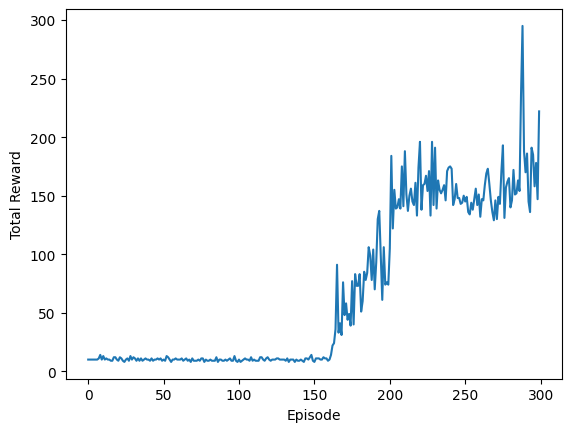

In [2]:
import copy
from dezero import Model
from dezero import optimizers
import dezero.functions as F
import dezero.layers as L
import gymnasium as gym
from collections import deque
import numpy as np
import random

class QNet(Model):
    def __init__(self, action_size):
        super().__init__()
        self.l1 = L.Linear(128)
        self.l2 = L.Linear(128)
        self.l3 = L.Linear(action_size)

    def forward(self, x):
        x = F.relu(self.l1(x))
        x = F.relu(self.l2(x))
        x = self.l3(x)
        return x
    
class ReplayBuffer:
    def __init__(self, buffer_size, batch_size):
        self.buffer = deque(maxlen=buffer_size)
        self.batch_size = batch_size

    def add(self, state, action, reward, next_state, done):
        data = (state, action, reward, next_state, done)
        self.buffer.append(data)

    def __len__(self):
        return len(self.buffer)
    
    def get_batch(self):
        data = random.sample(self.buffer, self.batch_size)

        state = np.stack([x[0] for x in data])
        action = np.array([x[1] for x in data])
        reward = np.array([x[2] for x in data])
        next_state = np.stack([x[3] for x in data])
        done = np.array([x[4] for x in data]).astype(np.int32)
        return state, action, reward, next_state, done

class DQNAgent:
    def __init__(self):
        self.gamma = 0.98
        self.lr = 0.0005
        self.epsilon = 0.1
        self.buffer_size = 10000
        self.batch_size = 32
        self.action_size = 2
        self.replay_buffer = ReplayBuffer(self.buffer_size, self.batch_size)
        self.qnet = QNet(self.action_size)
        self.qnet_target = QNet(self.action_size)
        self.optimizer = optimizers.Adam(self.lr)
        self.optimizer.setup(self.qnet)

    def sync_qnet(self):
        self.qnet_target = copy.deepcopy(self.qnet)

    def get_action(self, state):
        if np.random.rand() < self.epsilon:
            return np.random.choice(self.action_size)
        else:

            state = state[np.newaxis, :] # 将数条数据变成一行数列数据
            qs = self.qnet(state)
            return qs.data.argmax()
        
    def update(self, state, action, reward, next_state, done):
        self.replay_buffer.add(state, action, reward, next_state, done)
        if len(self.replay_buffer) < self.batch_size:
            return
        state, action, reward, next_state, done = self.replay_buffer.get_batch()
        qs = self.qnet(state)
        q = qs[np.arange(self.batch_size), action]
        next_qs = self.qnet_target(next_state)
        next_q = next_qs.max(axis=1)
        next_q.unchain()
        target = reward + (1 - done) * self.gamma * next_q
        loss = F.mean_squared_error(q, target) 

        self.qnet.cleargrads()
        loss.backward()
        self.optimizer.update()

episodes = 300
sync_interval = 20
env = gym.make('CartPole-v1')
agent = DQNAgent()
reward_history = []

for episode in range(episodes):
    state, _ = env.reset()
    done = False
    total_reward = 0

    while not done:
        action = agent.get_action(state)
        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        agent.update(state, action, reward, next_state, done)
        state = next_state
        total_reward += reward

    if episode % sync_interval == 0:
        agent.sync_qnet()

    reward_history.append(total_reward)



import matplotlib.pyplot as plt
plt.plot(range(episodes), reward_history)
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.show()

